# Ulrik Kinematics: Behavioral Structure Analysis

## Overview
This notebook provides a rigorous characterization of behavioral structure, focusing on **Kinematics** (Velocity, Acceleration) and **Syntax** (Entropy, Stereotypy). We analyze two datasets:
1.  **IFDN**: Determines the baseline phenotype of Dat-KI (Knock-in) vs WT mice.
2.  **AMPH**: Examines the interaction between Genotype and Amphetamine (Drug-induced stereotypy).

### Metrics Glossary
*   **Mean Velocity**: General locomotor activity/vigor.
*   **Entropy (Transition)**: The unpredictability of the next syllable. **Lower = More Stereotypic/Repetitive**.
*   **Stereotypy**: A normalized metric (1 - Entropy/Max_Entropy). **Higher = More Repetitive**.
*   **Entropy (Duration)**: How variable the length of behaviors is. 

## Rigor Standards
*   **Aggregation**: N = Animal (Session). We do not treat individual bouts as independent samples.
*   **Filtering**: UNK genotypes are removed. AMPH data is restricted to >5 mins post-injection.
*   **Fairness**: Syllable usage plots use "Sum-of-Ranks" sorting to ensure no group is visually marginalized.

---

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy import stats
from statannotations.Annotator import Annotator

# Suppress all warnings for clean output
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Add root to path for imports
root_dir = os.path.abspath(os.path.join(os.getcwd(), "../../../"))
if root_dir not in sys.path:
    sys.path.append(root_dir)
    sys.path.append(os.path.join(root_dir, "syllable_generation"))

from analysis.ulrik_kinematics.lib import loader, metrics

# Setup plotting style
sns.set_context("notebook", font_scale=1.2)
sns.set_style("whitegrid")

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PLOT_METRICS = ["mean_velocity", "mean_acceleration", "entropy_transition", "stereotypy", "entropy_duration"]

def add_stats_stars(ax, df, x, y, order, pairs, hue=None):
    try:
        annotator = Annotator(ax, pairs, data=df, x=x, y=y, hue=hue, order=order)
        annotator.configure(test='t-test_ind', text_format='star', loc='inside', verbose=0)
        annotator.apply_and_annotate()
    except Exception as e: pass

def get_fair_top_syllables(df, n=15):
    group_cols = ["Genotype"]
    if "Drug" in df.columns: group_cols.append("Drug")
    grouped = df.groupby(group_cols + ["Syllable"])["Frequency"].mean().reset_index()
    grouped["Rank"] = grouped.groupby(group_cols)["Frequency"].rank(method='min', ascending=False)
    rank_sums = grouped.groupby("Syllable")["Rank"].sum()
    return rank_sums.sort_values(ascending=True).head(n).index.tolist()

## Part 1: IFDN Analysis (WT vs KI)
We verify the core phenotype. Do KI mice move faster and act more predictably?

In [2]:
print("Loading IFDN Dataset...")
sessions_ifdn = loader.load_dataset("ifdn", base_dir=root_dir)

rows_ifdn = []
for s in tqdm(sessions_ifdn, desc="Processing IFDN"):
    rows_ifdn.append(metrics.analyze_session(s))
    
df_ifdn = pd.DataFrame(rows_ifdn)
# Filter
df_ifdn = df_ifdn[~df_ifdn["Genotype"].astype(str).isin(["None", "UNK", "nan"])]

Loading IFDN Dataset...


Processing IFDN:   0%|          | 0/19 [00:00<?, ?it/s]

### 1.1 Summary Stats
**Interpretation**:
*   **Stars**: Significance level (T-test). ns: p>0.05, *: p<0.05, **: p<0.01, ***: p<0.001.
*   **Velocity/Acceleration**: Expect HIGHER in KI.
*   **Stereotypy**: Expect HIGHER in KI.
*   **Entropy**: Expect LOWER in KI.

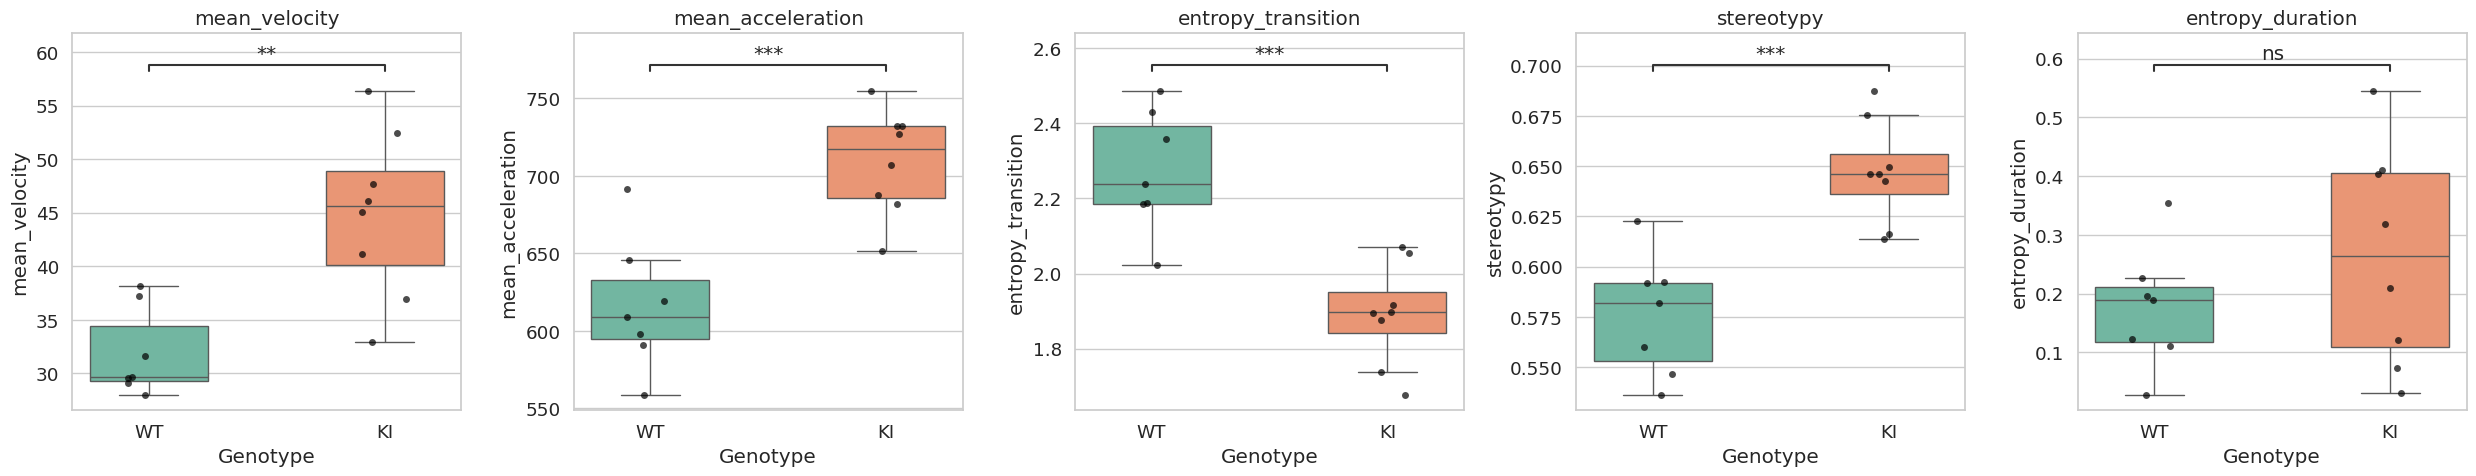

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
order = ["WT", "KI"]
pairs = [("WT", "KI")]

for i, m in enumerate(PLOT_METRICS):
    ax = axes[i]
    sns.boxplot(data=df_ifdn, x="Genotype", y=m, ax=ax, width=0.5, palette="Set2", showfliers=False, order=order)
    sns.stripplot(data=df_ifdn, x="Genotype", y=m, ax=ax, color="black", alpha=0.7, order=order)
    add_stats_stars(ax, df_ifdn, "Genotype", m, order, pairs)
    ax.set_title(m)

plt.tight_layout()
plt.show()

### 1.2 Syllable Usage (Fair Rank)
**Interpretation**:
We show the top 15 syllables. Sorting is done by **Sum of Ranks** across WT and KI. 
This prevents the plot from being dominated by "WT syllables" or "KI syllables" exclusively. 
Look for bars that are huge in Orange (KI) but small in Blue (WT) - these are the "Stereotypic Syllables".

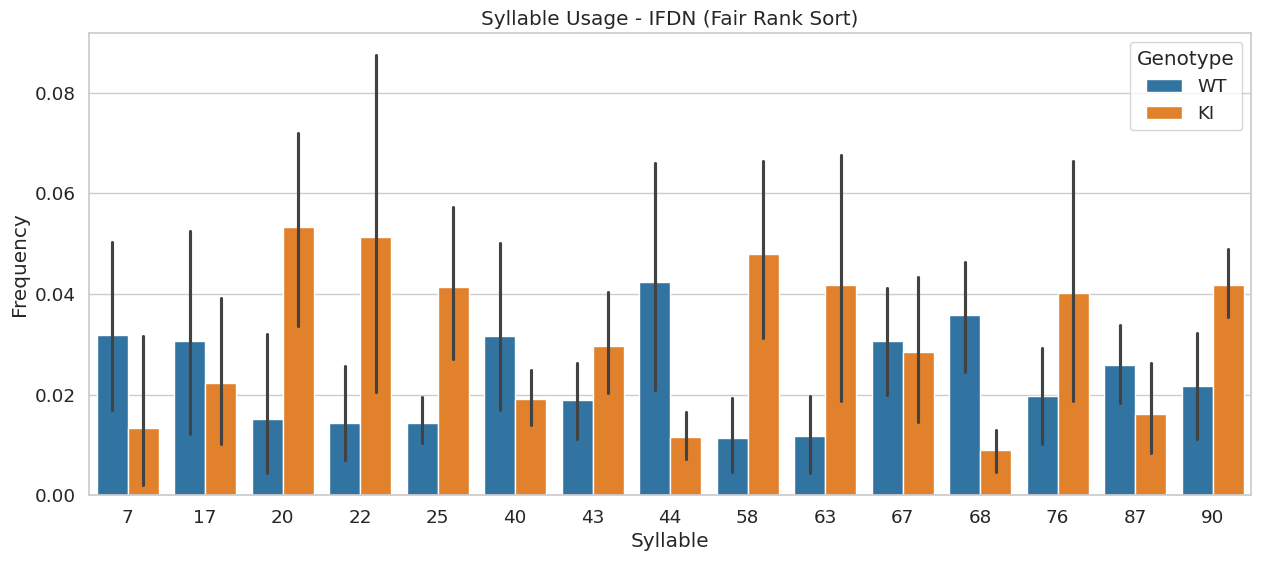

In [4]:
# Calculate Usage Dataframe FIRST
df_usage_ifdn = metrics.get_group_usage(sessions_ifdn)
# Filter Genotype
df_usage_ifdn = df_usage_ifdn[~df_usage_ifdn["Genotype"].astype(str).isin(["None", "UNK", "nan"])]

top_sylls = get_fair_top_syllables(df_usage_ifdn, n=15)
plot_df = df_usage_ifdn[df_usage_ifdn["Syllable"].isin(top_sylls)]

plt.figure(figsize=(15, 6))
sns.barplot(data=plot_df, x="Syllable", y="Frequency", hue="Genotype")
plt.title("Syllable Usage - IFDN (Fair Rank Sort)")
plt.show()

### 1.3 Transition Matrices
**Interpretation**:
Heatmaps show the probability of moving from Syllable X (Row) to Syllable Y (Column).
*   **WT Matrix**: Usually sparse but distributed (flexible syntax).
*   **KI Matrix**: Often shows "hot" squares or loops (A->B->A), indicating rigid sequences.

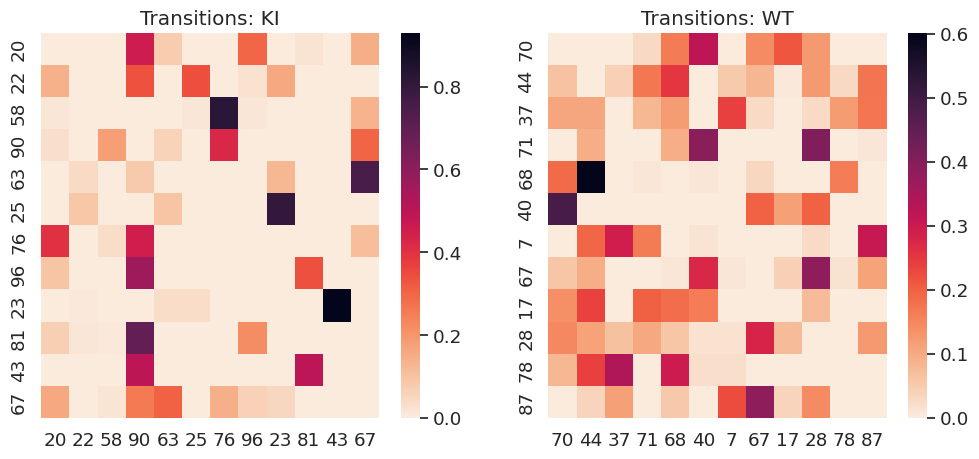

In [5]:
groups = sorted(df_ifdn["Genotype"].unique())
fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 5))
for i, g in enumerate(groups):
    g_sess = [s for s in sessions_ifdn if s.metadata.get('genotype') == g]
    matrix = metrics.get_group_transition_matrix(g_sess, top_n=12)
    sns.heatmap(matrix, ax=axes[i], cmap="rocket_r")
    axes[i].set_title(f"Transitions: {g}")
plt.show()

## Part 2: AMPH Analysis (Drug x Genotype)
Does Saline-KI look like Amph-WT? Does Amph affect KI mice?

In [6]:
print("Loading AMPH Dataset (Post-Injection Filtered)...")
sessions_amph = loader.load_dataset("amph", base_dir=root_dir, amph_post_injection_delay_min=5.0)

rows_amph = []
for s in tqdm(sessions_amph, desc="Processing AMPH"):
    rows_amph.append(metrics.analyze_session(s))

df_amph = pd.DataFrame(rows_amph)
# Filter
df_amph = df_amph[~df_amph["Genotype"].astype(str).isin(["None", "UNK", "nan"])]

Loading AMPH Dataset (Post-Injection Filtered)...


Processing AMPH:   0%|          | 0/30 [00:00<?, ?it/s]

### 2.1 Interaction Stats
**Interpretation**:
We compare four groups: WT-Sal, WT-Amph, KI-Sal, KI-Amph.
*   **WT Response**: Check WT-Sal vs WT-Amph (Red vs Blue on left). usually huge change.
*   **KI Response**: Check KI-Sal vs KI-Amph (Red vs Blue on right). usually smaller change (Ceiling Effect).

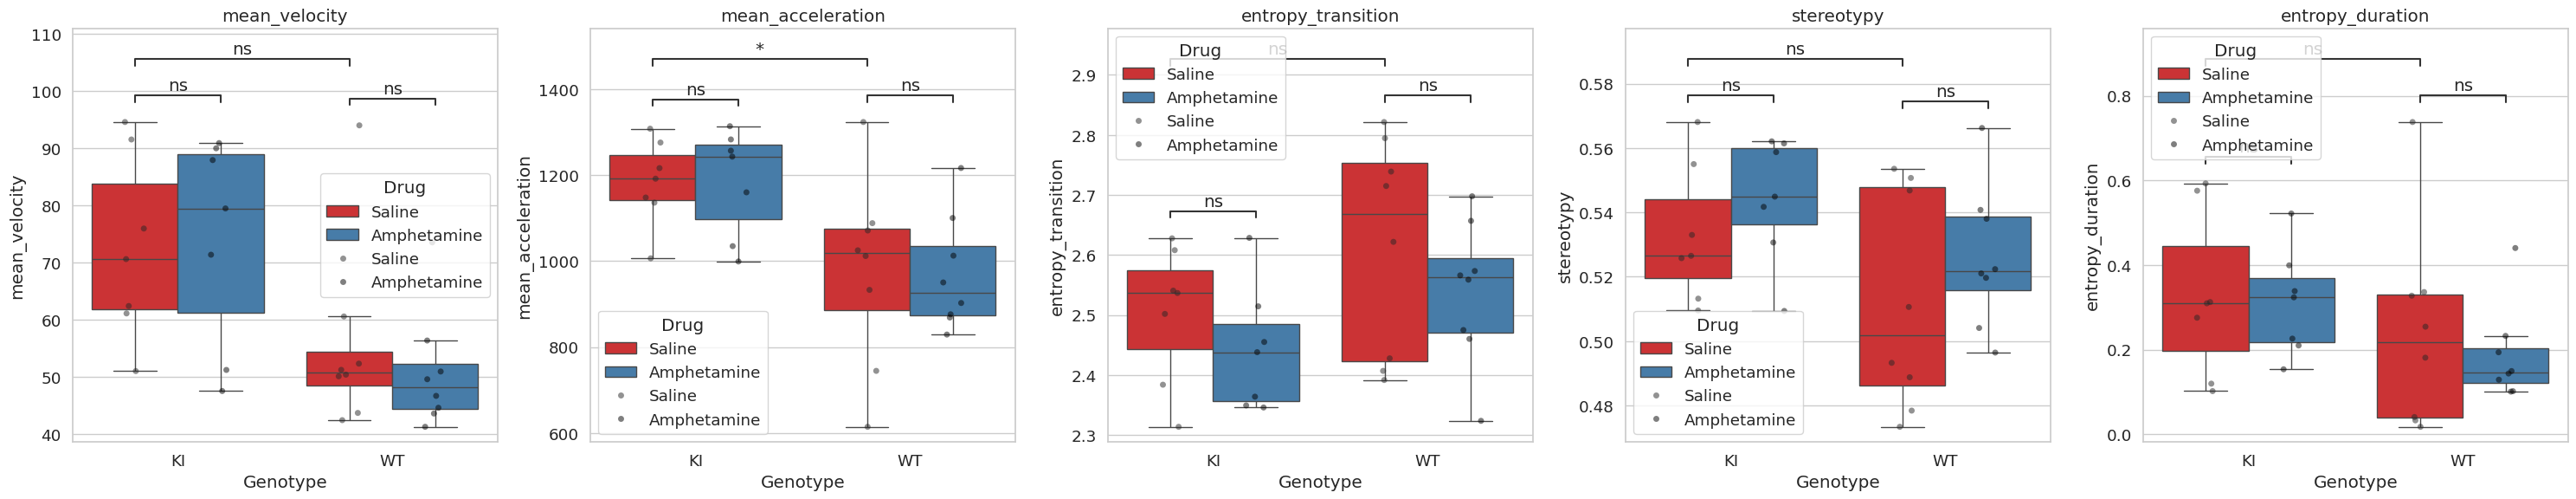

In [7]:
pairs = [
    (("WT", "Saline"), ("WT", "Amphetamine")),
    (("KI", "Saline"), ("KI", "Amphetamine")),
    (("WT", "Saline"), ("KI", "Saline"))
]

fig, axes = plt.subplots(1, 5, figsize=(30, 6))
for i, m in enumerate(PLOT_METRICS):
    # Complex hue trickery for annotator+boxplot
    ax = axes[i]
    sns.boxplot(data=df_amph, x="Genotype", y=m, hue="Drug", ax=ax, palette="Set1", showfliers=False)
    sns.stripplot(data=df_amph, x="Genotype", y=m, hue="Drug", ax=ax, dodge=True, color="black", alpha=0.5)
    add_stats_stars(ax, df_amph, "Genotype", m, ["WT", "KI"], pairs, hue="Drug")
    ax.set_title(m)
plt.tight_layout()
plt.show()

### 2.2 Syllable Usage (Fair Sorting by Group)

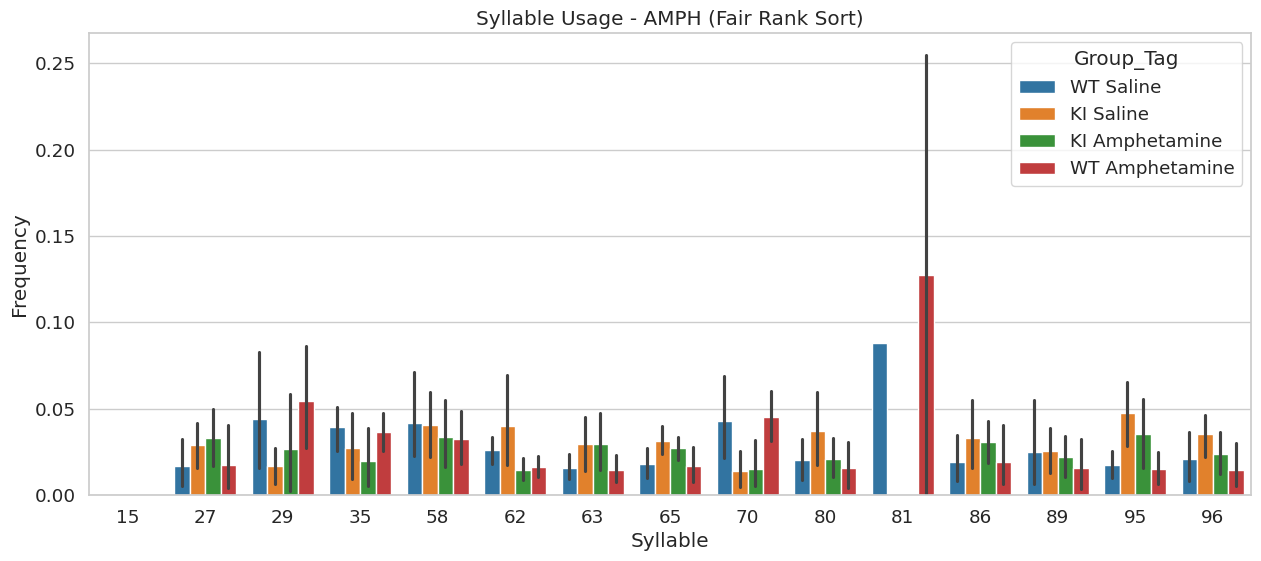

In [8]:
# Calculate Usage Dataframe FIRST
df_usage_amph = metrics.get_group_usage(sessions_amph)
df_usage_amph = df_usage_amph[~df_usage_amph["Genotype"].astype(str).isin(["None", "UNK", "nan"])]

top_sylls = get_fair_top_syllables(df_usage_amph, n=15)
plot_df = df_usage_amph[df_usage_amph["Syllable"].isin(top_sylls)]

plt.figure(figsize=(15, 6))
plot_df["Group_Tag"] = plot_df["Genotype"] + " " + plot_df["Drug"]
sns.barplot(data=plot_df, x="Syllable", y="Frequency", hue="Group_Tag")
plt.title("Syllable Usage - AMPH (Fair Rank Sort)")
plt.show()

### 2.3 Transition Deltas (The "Heatmap of Change")
**Interpretation**:
These plots show `Matrix(Amphetamine) - Matrix(Saline)`.
*   **Red Squares**: Transitions that become *more* frequent on drug.
*   **Blue Squares**: Transitions that are suppressed by drug.
*   **WT Delta**: Should look "noisy" or intense, showing massive reconfiguration.
*   **KI Delta**: Should look muted if the animal is already rigid/at-ceiling.

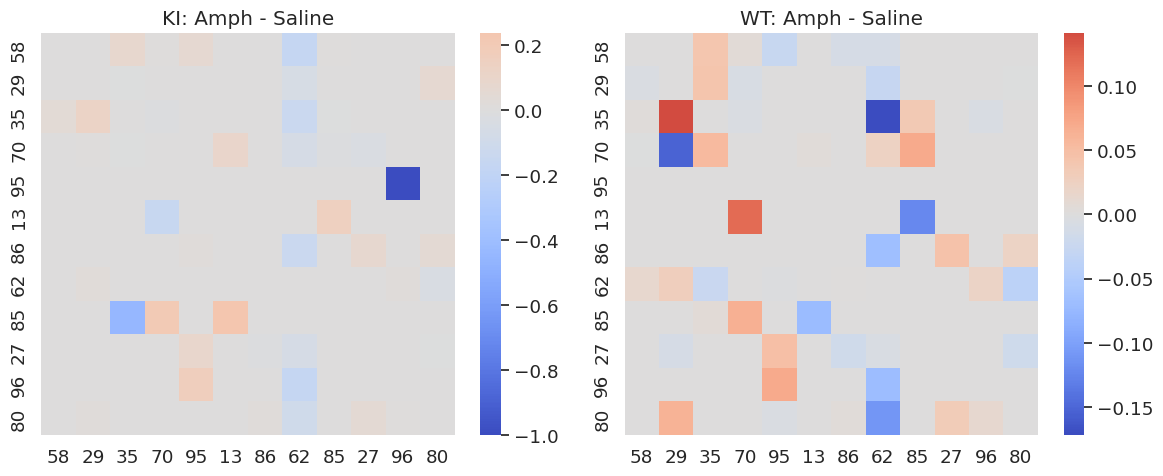

In [9]:
# Reusing logic from run_analysis.py for manual matrix calc
# 1. Get GLOBAL Top 12 Syllables (to align matrices)
all_sylls = []
for s in sessions_amph:
    if "syllable" in s.all_data_df.columns:
        all_sylls.append(s.all_data_df["syllable"].dropna())
global_counts = pd.concat(all_sylls).value_counts()
top_sylls_list = global_counts.head(12).index.tolist()

def calc_matrix(sess_list, slist):
    m = pd.DataFrame(0.0, index=slist, columns=slist)
    for s in sess_list:
        seq = s.all_data_df["syllable"].dropna().to_numpy()
        mask = np.concatenate(([True], seq[1:] != seq[:-1]))
        trans = seq[mask]
        for i in range(len(trans)-1):
            src, dst = trans[i], trans[i+1]
            if src in slist and dst in slist:
                m.loc[src, dst] += 1
    return m.div(m.sum(axis=1).replace(0, 1), axis=0)

genotypes = sorted(df_amph["Genotype"].unique())
fig, axes = plt.subplots(1, len(genotypes), figsize=(6 * len(genotypes), 5))

for i, g in enumerate(genotypes):
    sess_sal = [s for s in sessions_amph if s.metadata.get('genotype')==g and s.metadata.get('drug')=='Saline']
    sess_amph = [s for s in sessions_amph if s.metadata.get('genotype')==g and s.metadata.get('drug')=='Amphetamine']
    
    if sess_sal and sess_amph:
        delta = calc_matrix(sess_amph, top_sylls_list) - calc_matrix(sess_sal, top_sylls_list)
        sns.heatmap(delta, ax=axes[i], cmap="coolwarm", center=0)
        axes[i].set_title(f"{g}: Amph - Saline")

plt.tight_layout()
plt.show()